# Hwang et al. 2022 — PDAC
## Step 02 — Cell-state manifold (honest branching test -> curve)

**Test branching honestly** (BINDING): fit a scFates PPT **tree** and inspect branch nodes on the
embedding before deciding topology. A genuine bifurcation goes to Gate 3; only a truly non-branching
manifold gets a **curve**. Root from **developmental order** (Gast/pSom origin; Crest is late), never
a proliferation state. Signature scores are **graph-smoothed** for geography/correlation reads.

In [1]:
import os, sys, glob, time, warnings, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import scanpy as sc, scFates as scf
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
from scipy.stats import spearmanr
import matplotlib.pyplot as plt
sc.settings.verbosity = 1; SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd()); cat = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4)); pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars'); pth_feat = os.path.join(pth_data, 'features', 'biomart')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells | gate1 =', adata.uns.get('gate1'))
xy = adata.obsm['X_umap']; from numpy.linalg import svd
cc = xy - xy.mean(0); _,s,_ = svd(cc, full_matrices=False)
print(f'UMAP aspect ratio (major/minor std): {s[0]/s[1]:.2f}')

whole malignant manifold: 64401 cells | gate1 = GO
UMAP aspect ratio (major/minor std): 1.26


### Honest branching test — PPT tree, scan node counts
Fit the tree on the reference 2D UMAP basis at several `Nodes`, count branch nodes (degree>=3), and
read the **biology at each tip**. A real Y needs two competing arms — a high-Gast tip *and* a high-pSom
tip — diverging from a co-expressing hub.

In [4]:
def topo(ad):
    B = np.asarray(ad.uns['graph']['B']); deg=(B>0).sum(0)
    return int((deg==1).sum()), int((deg>=3).sum())
for Nodes in [30,50,80,120]:
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.tree(adata, method='ppt', Nodes=Nodes, ppt_lambda=2000, ppt_sigma=0.5, use_rep='X_umap', seed=SEED, plot=False)
    tp,fk = topo(adata); print(f'PPT tree Nodes={Nodes}: tips={tp}, branch nodes={fk}')

PPT tree Nodes=30: tips=8, branch nodes=6
PPT tree Nodes=50: tips=8, branch nodes=6
PPT tree Nodes=80: tips=9, branch nodes=7
PPT tree Nodes=120: tips=11, branch nodes=9


tip biology (cells within graph-dist<=3):
  tip 2: n= 3047 Gast=-0.0120 pSom=-0.0000 Crest=+0.0028
  tip 18: n= 2621 Gast=-0.0002 pSom=-0.0012 Crest=+0.0050
  tip 28: n= 1942 Gast=+0.0004 pSom=-0.0017 Crest=+0.0027
  tip 56: n= 2764 Gast=-0.0000 pSom=-0.0023 Crest=+0.0053
  tip 60: n= 2504 Gast=-0.0025 pSom=-0.0016 Crest=-0.0033
  tip 78: n= 2573 Gast=-0.0139 pSom=+0.0038 Crest=+0.0002
  tip 79: n= 2853 Gast=-0.0070 pSom=-0.0020 Crest=+0.0027
  tip 80: n= 2705 Gast=-0.0008 pSom=-0.0027 Crest=+0.0060
  tip 95: n= 2198 Gast=-0.0091 pSom=-0.0037 Crest=+0.0019
  tip 108: n= 2450 Gast=-0.0001 pSom=-0.0023 Crest=+0.0055
  tip 119: n= 2244 Gast=-0.0251 pSom=+0.0065 Crest=+0.0063


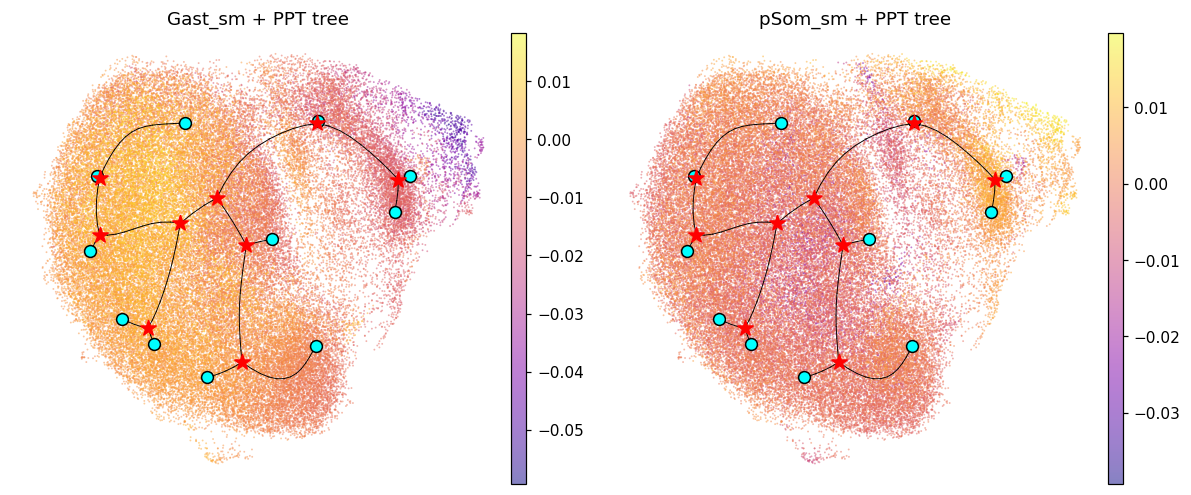

In [5]:
B = np.asarray(adata.uns['graph']['B']); F = adata.uns['graph']['F'].T
deg=(B>0).sum(0); tips=np.where(deg==1)[0]; forks=np.where(deg>=3)[0]
R = np.asarray(adata.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
print('tip biology (cells within graph-dist<=3):')
for tp in tips:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    print(f'  tip {tp}: n={m.sum():5d} Gast={adata.obs.Gast_sm[m].mean():+.4f} pSom={adata.obs.pSom_sm[m].mean():+.4f} Crest={adata.obs.Crest_sm[m].mean():+.4f}')
fig,ax=plt.subplots(1,2,figsize=(11,4.6))
for a_,col,ttl in zip(ax,['Gast_sm','pSom_sm'],['Gast_sm','pSom_sm']):
    sc.pl.umap(adata,color=col,cmap='plasma',size=6,alpha=.5,frameon=False,show=False,ax=a_,title=ttl+' + PPT tree')
    ii,jj=np.where(np.triu(B>0))
    for u,v in zip(ii,jj): a_.plot(F[[u,v],0],F[[u,v],1],'k-',lw=.6,zorder=4)
    a_.scatter(F[tips,0],F[tips,1],s=60,c='cyan',marker='o',edgecolor='k',zorder=6)
    if len(forks): a_.scatter(F[forks,0],F[forks,1],s=110,c='red',marker='*',zorder=6)
fig.tight_layout(); plt.show()

**Read — NON-BRANCHING.** The PPT tree reports 6-8 'branch nodes', but they are scattered in the
**dense interior of a filled 2-D cloud** — the algorithm carving up a blob, not a genuine Y (04_test
Chen2020 attempt 3: do not fit a tree on a strip/blob). Decisively, **the tip biology shows no
bifurcation**: every tip is weak and similar (all |Gast|,|pSom| < 0.03), with no high-Gast vs high-pSom
arm pair diverging from a co-expressing hub. The geography is a single monotone axis (Gast high one
side, pSom/Crest the other). -> fit a **curve**; Gate 3 = **NA**.

### Fit curve + fold check (off the committed embedding, edges rendered)
`fold self-approach` = min Euclidean distance between graph-distant node pairs / median edge length;
>1 means the curve does not fold back through the cloud (03_eval fork 4). We also render the curve
edges explicitly so topology is judged on the drawn curve, not a blind correlation (04_test Chen2020
attempt 6).

In [6]:
def fold_diag(ad):
    B=np.asarray(ad.uns['graph']['B']); F=ad.uns['graph']['F'].T
    G=shortest_path(sp.csr_matrix((B>0).astype(int)),unweighted=True)
    ii,jj=np.where(np.triu(B>0)); med=np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin=np.inf
    for a in range(F.shape[0]):
        for b in range(a+1,F.shape[0]):
            if G[a,b]>=3: dmin=min(dmin,np.sqrt(((F[a]-F[b])**2).sum()))
    return dmin/med, int(((B>0).sum(0)==1).sum()), int(((B>0).sum(0)>=3).sum())
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(adata, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa,tips_,forks_ = fold_diag(adata)
print(f'curve: tips={tips_} forks={forks_} | fold self-approach = {sa:.2f} (>1 = fold-free)')
assert forks_==0 and sa>1, 'topology check failed'

curve: tips=2 forks=0 | fold self-approach = 2.72 (>1 = fold-free)


### Root from developmental order (Gast/pSom-high tip, Crest-low)

In [7]:
B=np.asarray(adata.uns['graph']['B']); tps=np.where((B>0).sum(0)==1)[0]
R=np.asarray(adata.obsm['X_R']); hard=R.argmax(1)
D=shortest_path(sp.csr_matrix((B>0).astype(int)),unweighted=True); info={}
for tp in tps:
    m=np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp]=(adata.obs.Gast_sm[m].mean(),adata.obs.pSom_sm[m].mean(),adata.obs.Crest_sm[m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root=int(max(tps,key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low = developmental origin)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(adata, root); scf.tl.pseudotime(adata, n_map=1, seed=SEED)
t=adata.obs['t'].values
adata.obs['cyc']=adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate']).astype(float)
print('\npseudotime gradients (Spearman rho on smoothed scores):')
for s_ in ['Gast_sm','pSom_sm','Crest_sm','cyc']:
    rho,p=spearmanr(t,adata.obs[s_]); print(f'  {s_}: rho={rho:+.3f} p={p:.1e}')
print('root is developmental (cycling ~flat along pt), not a proliferation state')

tip 0: Gast=+0.0002 pSom=-0.0018 Crest=+0.0010
tip 2: Gast=-0.0151 pSom=+0.0020 Crest=+0.0030
derived root = tip 0 (Gast/pSom-high, Crest-low = developmental origin)

pseudotime gradients (Spearman rho on smoothed scores):
  Gast_sm: rho=-0.655 p=0.0e+00
  pSom_sm: rho=+0.111 p=8.4e-175
  Crest_sm: rho=+0.144 p=6.3e-295
  cyc: rho=-0.025 p=1.1e-10
root is developmental (cycling ~flat along pt), not a proliferation state


### Orientation for the house linear layout (pseudotime left -> right)

In [8]:
xy = adata.obsm['X_umap'].copy(); t = adata.obs['t'].values
xyr = np.column_stack([xy[:,0], xy[:,1]])
r = float(np.corrcoef(xyr[:,0], t)[0,1])
if r < 0: xyr[:,0] = -xyr[:,0]; r = -r
adata.obsm['X_umap_lin'] = xyr
print(f'orientation: corr(x_lin, pseudotime) = {r:+.2f} (low pt -> left)')

orientation: corr(x_lin, pseudotime) = +0.94 (low pt -> left)


### Save manifold + `manifold.pdf` (pseudotime, curve fold-free)

saved manifold.h5ad + manifold.pdf | geometry: Linear-pSom/Crest


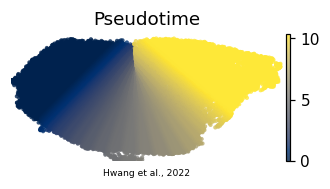

In [9]:
adata.uns['epg'] = {'NodePositions': np.asarray(adata.uns['epg']['NodePositions'])}
adata.uns['geometry']='Linear-pSom/Crest'; adata.uns['root']=int(root)
adata.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = adata.obsm['X_umap_lin']
xlo,xhi=np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi=np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right', frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Hwang et al., 2022', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight'); plt.show()
print('saved manifold.h5ad + manifold.pdf | geometry:', adata.uns['geometry'])